# TP 1 : Etude sur les dépendances entre les variables/individus 


## Présentation de l'étude 

Les alcools de structures différentes sont fréquemment utilisés dans les produits d'hygiène et les cosmétiques. Il est souhaitable de classer ces alcools afin d'évaluer leurs effets nocifs potentiels à l'aide de méthodes moins coûteuses.
5 gaz sont particulièrement intéressants d'identifier : 

- 1-octanol, connu sous le nom d'alcool gras, avec son odeur forte, généralement utilisé dans les parfums et arômes;
- 1-propanol, ressemble beaucoup à l'alcool éthylique chimiquement avec une odeur forte et toxique, plutôt utilisé comme solvant;
- 2-butanol, alcool secondaire, est un solvant puissant;
- 2-propanol, alcool secondaire utilisé à la maison et dans l'industrie;
- 1-isobutanol, utilisé comme solvant.  

Le capteur QCM  (microbalance de cristal de quartz) est un dispositif physique qui est sensible aux changements de fréquence de résonance. Le but de l'étude est de mesurer l'action de différents capteurs QCM sur ces 5 alcools différents, et de déterminer quel type de capteur est le plus efficace dans la classification de ces alcools.

## Présentation des capteurs utilisés et des données générées

Pour cela, cinq capteurs QCM de gaz différents (QCM3, QCM6, QCM7, QCM10, QCM12) sont utilisés et cinq mesures de gaz différentes (1-octanol , 1-propanol, 2-butanol, 2-propanol et 1-isobutanol) sont effectuées pour chacun de ces capteurs.

L'échantillon de gaz passe à travers le capteur en cinq concentrations différentes. Ces concentrations sont :
  
    Rapport d'air (ml)   Rapport de gaz (ml) 
    0.799                0.201 
    0.700                0.300 
    0.600                0.400 
    0.501                0.499 
    0.400                0.600 

Les rapports  sur les polymères à empreintes moléculaires (MIP) et les nanoparticules (NP) utilisés dans les capteurs QCM sont :

    Capteur	 Ratio MIP   Ratio NP
      QCM3	      1	        1 
      QCM6          1	        0 
      QCM7	      1	        0.5 
      QCM10	     1            2 
      QCM12	     0	        1
      

## Références 

**Dataset :** https://archive.ics.uci.edu/ml/datasets/Alcohol+QCM+Sensor+Dataset

**Article :** M. Fatih Adak, Peter Lieberzeit, Purim Jarujamrus, Nejat Yumusak, *Classification of alcohols obtained by QCM sensors with different characteristics using ABC based neural network*, Engineering Science and Technology, an International Journal, 2019.
https://www.sciencedirect.com/science/article/pii/S2215098619303337?via%3Dihub


In [20]:
import numpy as np
from io import StringIO

## Partie I : Importer les données d'un capteur QCM

In [27]:
# Afficher l'entête du jeu de données du capteur QCM3
fichier=open('QCM3.csv', "r")
print(fichier.readline())

# Charger l'ensemble de données et stocker dans la matrice Data
Data = np.genfromtxt('QCM3.csv',delimiter=";",skip_header=1)

# Afficher le jeu de données
print(Data)

# Afficher les dimensions de la matrice des données
print("Dimensions de la matrice de donnees", Data.shape)

"0.799_0.201";"0.799_0.201";"0.700_0.300";"0.700_0.300";"0.600_0.400";"0.600_0.400";"0.501_0.499";"0.501_0.499";"0.400_0.600";"0.400_0.600";"1-Octanol";"1-Propanol";"2-Butanol";"2-propanol";"1-isobutanol"

[[ -10.06  -10.62  -14.43  -18.31  -24.64  -30.56  -38.62  -45.59  -54.89
   -62.28    1.      0.      0.      0.      0.  ]
 [  -9.69  -10.86  -16.73  -21.75  -28.47  -35.83  -43.65  -52.43  -61.92
   -71.27    1.      0.      0.      0.      0.  ]
 [ -12.07  -14.28  -21.54  -27.92  -35.19  -43.94  -52.04  -62.49  -71.97
   -83.1     1.      0.      0.      0.      0.  ]
 [ -14.21  -17.41  -25.91  -33.36  -41.29  -51.27  -59.94  -71.55  -81.51
   -93.83    1.      0.      0.      0.      0.  ]
 [ -16.57  -20.35  -29.97  -37.84  -47.03  -57.29  -67.13  -78.96  -90.01
  -102.65    1.      0.      0.      0.      0.  ]
 [ -75.61  -64.1  -122.08 -102.17 -174.79 -145.5  -214.69 -177.3  -250.83
  -207.99    0.      1.      0.      0.      0.  ]
 [ -76.28  -64.53 -123.4  -103.06 -174.74 -1

In [21]:
# Afficher l'entête du jeu de données du capteur QCM6
fichier=open('QCM6.csv', "r")
print(fichier.readline())

# Charger l'ensemble de données et stocker dans la matrice Data
DataQCM6 = np.genfromtxt('QCM6.csv',delimiter=";",skip_header=1)

# Afficher le jeu de données
print(DataQCM6)

# Afficher les dimensions de la matrice des données
print("Dimensions de la matrice de donnees", DataQCM6.shape)

"0.799_0.201";"0.799_0.201";"0.700_0.300";"0.700_0.300";"0.600_0.400";"0.600_0.400";"0.501_0.499";"0.501_0.499";"0.400_0.600";"0.400_0.600";"1-Octanol";"1-Propanol";"2-Butanol";"2-propanol";"1-isobutanol"

[[ -11.82  -13.29  -19.32  -26.28  -38.14  -50.09  -59.78  -75.04  -85.63
  -104.66    1.      0.      0.      0.      0.  ]
 [ -11.54  -14.18  -25.35  -32.75  -48.77  -60.08  -75.41  -89.72 -104.25
  -121.9     1.      0.      0.      0.      0.  ]
 [ -12.45  -15.81  -33.33  -40.64  -61.5   -72.12  -91.75 -104.67 -124.21
  -139.76    1.      0.      0.      0.      0.  ]
 [ -14.67  -18.49  -40.56  -47.67  -72.11  -82.19 -106.26 -118.26 -141.95
  -155.84    1.      0.      0.      0.      0.  ]
 [ -18.07  -19.74  -47.08  -53.5   -81.15  -89.81 -117.91 -128.1  -156.66
  -168.72    1.      0.      0.      0.      0.  ]
 [ -98.63  -97.92 -137.15 -131.93 -191.17 -180.52 -260.06 -240.69 -352.22
  -321.2     0.      1.      0.      0.      0.  ]
 [ -96.62  -96.5  -136.86 -131.75 -192.76 -1

# Partie II : Premières représentations des données

In [11]:
import matplotlib.pyplot as plt

### Afficher la distribution des données via des boîtes à moustaches (Boxplot)

Représentation regroupant des statistiques classiques sur une variable :

<img src="./boxplot.png" width="500" height="500"  >

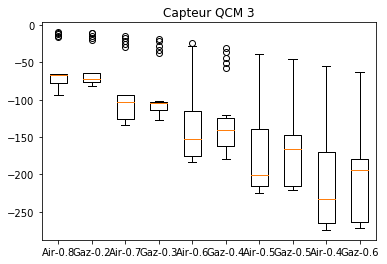

In [12]:
#red_square = dict(markerfacecolor='r', marker='s')
fig1, ax1 = plt.subplots()
ax1.set_title('Capteur QCM 3')
Nom=["Air-0.8","Gaz-0.2","Air-0.7","Gaz-0.3","Air-0.6","Gaz-0.4","Air-0.5","Gaz-0.5","Air-0.4","Gaz-0.6"]
ax1.boxplot(Data[:,:10],labels=Nom,showfliers=True)

plt.show()



[0 2 4 6 8]
[[ -10.06  -14.43  -24.64  -38.62  -54.89]
 [  -9.69  -16.73  -28.47  -43.65  -61.92]
 [ -12.07  -21.54  -35.19  -52.04  -71.97]
 [ -14.21  -25.91  -41.29  -59.94  -81.51]
 [ -16.57  -29.97  -47.03  -67.13  -90.01]
 [ -75.61 -122.08 -174.79 -214.69 -250.83]
 [ -76.28 -123.4  -174.74 -206.75 -240.14]
 [ -76.96 -124.5  -169.93 -200.89 -232.82]
 [ -78.29 -125.78 -165.42 -196.1  -226.89]
 [ -79.62 -126.61 -162.73 -194.87 -221.33]
 [ -88.03 -128.47 -177.13 -220.91 -274.27]
 [ -91.08 -131.32 -182.66 -224.73 -272.67]
 [ -92.08 -132.5  -183.33 -222.6  -264.81]
 [ -92.58 -133.54 -182.34 -217.73 -255.14]
 [ -93.29 -133.96 -178.29 -211.85 -248.13]
 [ -68.84  -97.04 -128.66 -152.78 -185.98]
 [ -67.95  -95.08 -123.29 -146.27 -176.94]
 [ -67.29  -94.75 -118.7  -142.31 -172.51]
 [ -66.38  -93.75 -114.96 -139.18 -170.52]
 [ -66.12  -93.09 -111.78 -136.83 -168.05]
 [ -65.56 -100.34 -148.72 -208.83 -268.57]
 [ -65.95 -101.82 -151.04 -211.86 -269.62]
 [ -66.42 -103.32 -152.73 -215.4  -269.84]

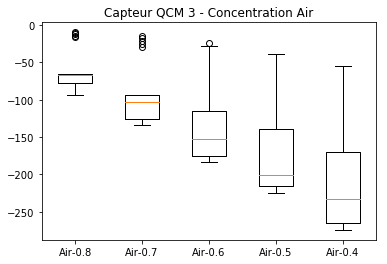

In [13]:
# Etude sur la concentration d'Air dans le capteur : 

listeAir=np.arange(0,10,2,dtype=int)
print(listeAir)
print(Data[:,listeAir])
DataAir=Data[:,listeAir]

fig2, ax2 = plt.subplots()
ax2.set_title('Capteur QCM 3 - Concentration Air')
NomAir=["Air-0.8","Air-0.7","Air-0.6","Air-0.5","Air-0.4"]
ax2.boxplot(DataAir,labels=NomAir,showfliers=True)

plt.show()

[1 3 5 7 9]
[[ -10.62  -18.31  -30.56  -45.59  -62.28]
 [ -10.86  -21.75  -35.83  -52.43  -71.27]
 [ -14.28  -27.92  -43.94  -62.49  -83.1 ]
 [ -17.41  -33.36  -51.27  -71.55  -93.83]
 [ -20.35  -37.84  -57.29  -78.96 -102.65]
 [ -64.1  -102.17 -145.5  -177.3  -207.99]
 [ -64.53 -103.06 -144.98 -170.68 -200.05]
 [ -65.37 -103.87 -140.56 -165.88 -194.7 ]
 [ -66.49 -104.77 -136.17 -161.99 -189.57]
 [ -66.85 -104.38 -133.26 -160.68 -183.81]
 [ -76.88 -124.36 -175.21 -218.92 -268.55]
 [ -79.42 -125.91 -178.76 -221.49 -266.15]
 [ -80.56 -126.99 -179.25 -219.52 -259.99]
 [ -81.3  -127.76 -177.94 -215.09 -251.88]
 [ -81.88 -127.68 -173.59 -209.7  -245.84]
 [ -78.   -107.38 -138.16 -159.83 -191.71]
 [ -76.82 -105.21 -132.91 -153.75 -184.07]
 [ -75.99 -104.77 -128.29 -150.07 -180.33]
 [ -74.97 -103.66 -124.23 -147.22 -178.7 ]
 [ -74.25 -102.5  -120.95 -145.02 -175.16]
 [ -71.66 -109.75 -157.43 -212.29 -268.95]
 [ -72.17 -111.37 -159.59 -214.85 -270.97]
 [ -72.72 -112.74 -161.12 -217.42 -271.73]

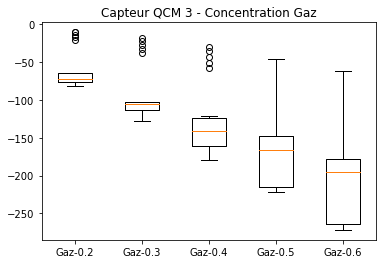

In [22]:
# Etude sur la concentration de gaz dans le capteur : 

listeGaz=np.arange(1,10,2,dtype=int)
print(listeGaz)
print(Data[:,listeGaz])
DataGaz=Data[:,listeGaz]

fig3, ax3 = plt.subplots()
ax3.set_title('Capteur QCM 3 - Concentration Gaz')
NomGaz=["Gaz-0.2","Gaz-0.3","Gaz-0.4","Gaz-0.5","Gaz-0.6"]
ax3.boxplot(DataGaz,labels=NomGaz,showfliers=True)

plt.show()

# Partie III : Etude des dépendances entre les concentrations gaz et air

In [15]:
#import scipy as sc


## 1) Matrice de variance-covariance $\Sigma$ 
Soit $X$ le tableau des données de dimensions $n \times p$ d'élément $x_{ij}$ construit à partir de $n$ individus définis par $p$ variables.
On définit l'individu moyen $g$ par le vecteur de $\mathbb{R}^p$ par :  $g=\left[\overline{x_1},..,\overline{x_p}\right]$ avec 
$$\overline{x_j}=\frac{1}{n}\sum_{k=1}^p x_{kj},\ \forall j\in \{1,..,p\}.$$

Soit maintenant $X_C$ le tableau centré en $g$ de dimensions $n\times p$ défini par : $X_{C_{ij}}=x_{ij}-\overline{x_j}, \forall i\in \{1,..,n\}, \forall j\in \{1,..,p\}$.


<img src="./Xc.png" width="500" height="500"  >

On appelle *la matrice de variance-covariance*,  la matrice symétrique de dimension $p\times p$ dont les éléments diagonaux représentent la variance des variables et les éléments hors diagonaux la covariance entre les variables : 

$$\Sigma=\frac{1}{n}X_C^T X_C$$

La covariance de la variable $j$ et $l$, notée $\Sigma_{jl}$, mesure la liaison/dépendance des paramètres :

$$\Sigma_{jl}=\frac{1}{n}\sum_{i=1}^n(x_{ij}-\overline{x_j})(x_{il}-\overline{x_l})$$




matrice de variance-covariance [[ 337.93517   386.836255  439.765605 ... 1449.678215 1429.885215
  1387.733575]
 [ 386.836255  443.56412   504.86292  ... 1668.38521  1646.28821
  1598.24165 ]
 [ 439.765605  504.86292   575.17397  ... 1904.87186  1880.355835
  1826.132325]
 ...
 [1449.678215 1668.38521  1904.87186  ... 6344.47078  6269.16488
  6095.3902  ]
 [1429.885215 1646.28821  1880.355835 ... 6269.16488  6195.89403
  6025.43305 ]
 [1387.733575 1598.24165  1826.132325 ... 6095.3902   6025.43305
  5861.38955 ]]


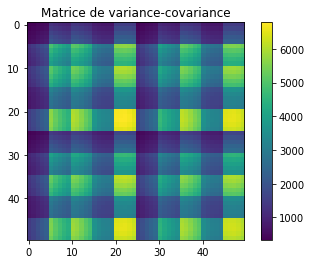

In [16]:
#  Calcul de la matrice de variance-covariance
S=np.cov(DataAir,DataGaz)

#Affichage de la matrice comme une image
print('matrice de variance-covariance', S)
fig4, ax4 = plt.subplots()
ax4.set_aspect('equal')
ax4.set_title('Matrice de variance-covariance')
plt.imshow(S)
plt.colorbar()
plt.show()

## 2) Corrélation entre deux variables

A partir de cette matrice $\Sigma$, on définit aussi *la corrélation entre les variables $X$ et* $Y$, indépendant des unités de mesure de X et de Y. Le coefficient de corrélation est symétrique :
$$-1\leq Corr(X,Y)=\frac{Cov(X,Y)}{\sigma_X \sigma_Y}\leq 1$$

- $Corr(X,Y)=0$, les variables sont quasiment décorrélées c'est-à-dire étant donné $X$, on ne peut rien dire.prédire sur la valeur de $Y$.
- $Corr(X,Y)=1$, dépendance linéaire positive de $X$ et $Y$.
- $Corr(X,Y)=-1$, dépendance linéaire négative de $X$ et $Y$.



matrice de correlation [[1.         0.99915363 0.99748173 ... 0.9900502  0.98817187 0.98602768]
 [0.99915363 1.         0.9995296  ... 0.99453581 0.99306042 0.99120606]
 [0.99748173 0.9995296  1.         ... 0.99716828 0.99606674 0.99456309]
 ...
 [0.9900502  0.99453581 0.99716828 ... 1.         0.9999079  0.99954769]
 [0.98817187 0.99306042 0.99606674 ... 0.9999079  1.         0.9998526 ]
 [0.98602768 0.99120606 0.99456309 ... 0.99954769 0.9998526  1.        ]]


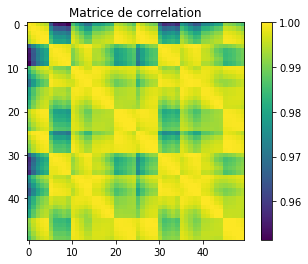

In [17]:
# Calcul de la matrice de Corrélation
C=np.corrcoef(DataAir,DataGaz)

# affichage de la matrice comme une image
print('matrice de correlation', C)
fig5, ax5 = plt.subplots()
ax5.set_aspect('equal')
ax5.set_title('Matrice de correlation')
plt.imshow(C)
plt.colorbar()
plt.show()

# Partie IV : Travail demandé 

- Réaliser une étude sur les dépendances entre les différents gaz en considérant la transposée de la matrice (*np.transpose*)
- Réaliser la même étude sur les autres capteurs QCM

matrice de variance-covariance Gaz [[ 7.50790976e+02  6.37367079e+02  1.08743539e+03  9.44096192e+02
   1.42451917e+03  1.23946214e+03  1.63838310e+03  1.42203631e+03
   1.84562670e+03  1.59964272e+03  1.05093333e+01 -2.99733333e+00
  -5.92650000e+00 -9.06500000e-01 -6.79000000e-01]
 [ 6.37367079e+02  6.04379422e+02  9.05111649e+02  8.59280913e+02
   1.17797620e+03  1.10510048e+03  1.39450323e+03  1.28906742e+03
   1.60307409e+03  1.47873377e+03  9.80091667e+00 -7.74916667e-01
  -3.80408333e+00 -2.97033333e+00 -2.25158333e+00]
 [ 1.08743539e+03  9.05111649e+02  1.60703201e+03  1.35994982e+03
   2.12741959e+03  1.80317760e+03  2.46611151e+03  2.08330002e+03
   2.77250020e+03  2.34213297e+03  1.53059167e+01 -6.10200000e+00
  -7.66116667e+00  9.21666667e-02 -1.63491667e+00]
 [ 9.44096192e+02  8.59280913e+02  1.35994982e+03  1.25594000e+03
   1.80208516e+03  1.65612031e+03  2.15033832e+03  1.95645100e+03
   2.47297429e+03  2.24794582e+03  1.39883333e+01 -1.80625000e+00
  -6.57500000e+00 -2

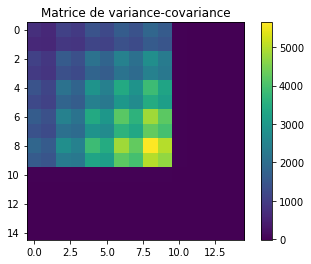

In [24]:
#  Calcul de la matrice de variance-covariance
S_gaz=np.cov(np.transpose(Data))


#Affichage de la matrice comme une image
print('matrice de variance-covariance Gaz', S)
fig5, ax5 = plt.subplots()
ax5.set_aspect('equal')
ax5.set_title('Matrice de variance-covariance')
plt.imshow(S_gaz)
plt.colorbar()
plt.show()

matrice de variance-covariance Gaz [[1.         0.99917042 0.9976457  0.99631947 0.99565406 0.88976287
  0.87848541 0.87569296 0.87172324 0.86261859 0.97133936 0.96612015
  0.96223968 0.95773619 0.95801045 0.9799148  0.98077629 0.98252894
  0.98472979 0.98545462 0.98837183 0.98780195 0.9867412  0.98516126
  0.9827872 ]
 [0.99917042 1.         0.99958556 0.99891219 0.99845905 0.8902398
  0.87998416 0.87730279 0.87323516 0.86406877 0.97312206 0.96828725
  0.96513911 0.96146639 0.9618561  0.98474146 0.98587322 0.98757593
  0.98932128 0.98971321 0.98840705 0.9880953  0.98723834 0.9860772
  0.9839854 ]
 [0.9976457  0.99958556 1.         0.99983304 0.99957122 0.89028851
  0.88064221 0.87793664 0.87371539 0.86459689 0.97345451 0.96902408
  0.96644543 0.9633548  0.96373017 0.98744098 0.98871618 0.99027454
  0.99158411 0.99172318 0.98787425 0.98777867 0.98713594 0.98633413
  0.98452881]
 [0.99631947 0.99891219 0.99983304 1.         0.99990671 0.89178831
  0.88254822 0.87983933 0.87554851 0.8665

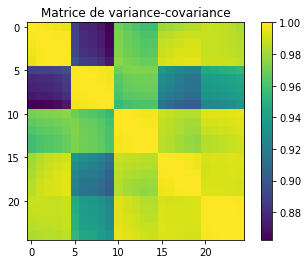

In [31]:
# Calcul de la matrice de Corrélation
#C_gaz=np.corrcoef(np.transpose(Data[:,:10]))

T=np.transpose(Data[:,:10])
C_gaz=np.corrcoef(Data[:,:10])


#Affichage de la matrice comme une image
print('matrice de variance-covariance Gaz', C_gaz)
fig5, ax5 = plt.subplots()
ax5.set_aspect('equal')
ax5.set_title('Matrice de variance-covariance')
plt.imshow(C_gaz)
plt.colorbar()
plt.show()